<a href="https://colab.research.google.com/github/araujoluigif/Machine-Learning/blob/main/ML_Wines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 2 – Machine Learning & Modelling: K-means no dataset Wines

**Integrantes:**
- Luigi Francisco RM:571204

- Breno Filipe RM:571824

- Igor Cypriano RM:570353

- Diogo Lopes RM:570732

## a) Introdução
**Problema:** temos 178 vinhos da mesma região da Itália, descritos por 13 medidas químicas
(teor alcoólico, acidez, fenóis, cor, prolina etc.). Queremos descobrir se existem grupos
naturais de vinhos parecidos entre si, **sem usar o rótulo de classe**.

**Solução proposta:** aplicar o algoritmo **K-means**, um método de aprendizado não supervisionado
que agrupa observações pela distância entre elas. Etapas:
1. Pré-processamento (remover a coluna de classe, checar nulos, padronizar);
2. Escolha do número de grupos com o **Método Elbow** e o **Silhouette Score**;
3. Ajuste do modelo final;
4. Análise das características de cada grupo (teor alcoólico, acidez, cor etc.).




In [ ]:
# Bibliotecas usadas no projeto
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Carrega o dataset direto do GitHub (versão Raw do gist), sem precisar baixar arquivo
url = "https://gist.githubusercontent.com/tijptjik/9408623/raw/b237fa5848349a14a14e5d4107dc7897c21951f5/wine.csv"
base = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
local = base / 'wine.csv'
df = pd.read_csv(local if local.exists() else url)
assert df.shape == (178, 14), 'Confira o formato da base Wine.'

# Renomeia as colunas abreviadas para nomes mais claros
df.columns = ['Classe', 'Alcool', 'Acido_Malico', 'Cinzas', 'Alcalinidade_Cinzas',
              'Magnesio', 'Fenois_Totais', 'Flavonoides', 'Fenois_Nao_Flavonoides',
              'Proantocianinas', 'Intensidade_Cor', 'Matiz', 'OD280_OD315', 'Prolina']

print(df.shape)   # esperado: 178 linhas e 14 colunas
df.head()

(178, 14)


In [ ]:
# ---------- b) Pré-processamento ----------

# 1) Exclusão da feature de classe:
# 'Classe' é o rótulo (a variedade da uva). O K-means é não supervisionado,
# então o rótulo não pode entrar no modelo e é removido.
X = df.drop(columns=['Classe'])

assert X.select_dtypes(include='number').shape[1] == 13
assert not X.isna().any().any(), 'Há nulos: revisar tratamento antes do ajuste.'
print('Linhas duplicadas:', X.duplicated().sum())

# 2) Tratamento de nulos:
# Verificamos se há valores ausentes em cada coluna.
print("Valores nulos por coluna:")
print(X.isnull().sum())
# Resultado: nenhuma coluna tem nulos, então não é preciso remover ou imputar dados.

# 3) Padronização:
# As variáveis estão em escalas muito diferentes (Prolina chega a ~1600, Matiz fica perto de 1).
# Como o K-means usa distância euclidiana, sem padronizar a Prolina dominaria o agrupamento.
# O StandardScaler deixa cada variável com média 0 e desvio padrão 1.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nMédias após padronização (≈0):", X_scaled.mean(axis=0).round(2))
print("Desvios após padronização (≈1):", X_scaled.std(axis=0).round(2))

Linhas duplicadas: 0
Valores nulos por coluna:
Alcool                    0
Acido_Malico              0
Cinzas                    0
Alcalinidade_Cinzas       0
Magnesio                  0
Fenois_Totais             0
Flavonoides               0
Fenois_Nao_Flavonoides    0
Proantocianinas           0
Intensidade_Cor           0
Matiz                     0
OD280_OD315               0
Prolina                   0
dtype: int64

Médias após padronização (≈0): [-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]
Desvios após padronização (≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


k = 2: silhueta = 0.259
k = 3: silhueta = 0.285
k = 4: silhueta = 0.260
k = 5: silhueta = 0.202
k = 6: silhueta = 0.237
k = 7: silhueta = 0.204
k = 8: silhueta = 0.157
k = 9: silhueta = 0.150
k = 10: silhueta = 0.144


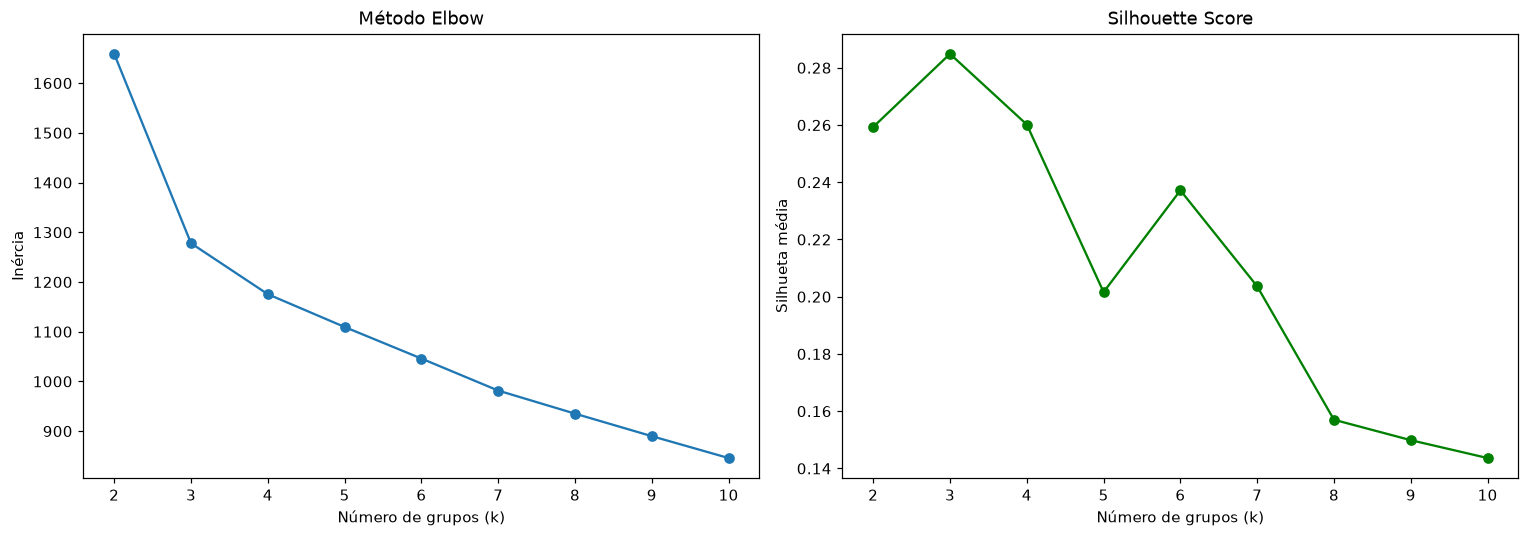

In [ ]:
# ---------- d) Número ideal de grupos ----------
# Testamos k de 2 a 10 e guardamos:
# - Inércia (soma das distâncias ao quadrado dentro dos grupos), usada no Elbow
# - Silhouette Score (de -1 a 1; quanto maior, mais separados e coesos os grupos)
inercias = []
silhuetas = []
ks = range(2, 11)

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(ks, inercias, marker='o')
ax[0].set_title('Método Elbow')
ax[0].set_xlabel('Número de grupos (k)')
ax[0].set_ylabel('Inércia')

ax[1].plot(ks, silhuetas, marker='o', color='green')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Número de grupos (k)')
ax[1].set_ylabel('Silhueta média')

plt.tight_layout()
plt.show()

for k, s in zip(ks, silhuetas):
    print(f"k = {k}: silhueta = {s:.3f}")

# Interpretação:
# - Elbow: a inércia cai muito de k=2 para k=3 e, a partir daí, a queda fica bem mais suave.
#   O "cotovelo" está em k=3.
# - Silhueta: o maior valor aparece em k=3 (≈0,285).
# Os dois métodos concordam, então escolhemos k = 3.

In [ ]:
# ---------- c) Ajuste do K-means ----------
# Modelo final com k=3.
# n_init=10: o algoritmo roda 10 vezes com centroides iniciais diferentes e fica com o melhor.
# random_state=42: garante que o resultado seja o mesmo toda vez que rodar.
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df['Grupo'] = kmeans.fit_predict(X_scaled)

print("Quantidade de vinhos por grupo:")
print(df['Grupo'].value_counts().sort_index())
print(f"\nSilhouette Score do modelo final: {silhouette_score(X_scaled, df['Grupo']):.3f}")

Quantidade de vinhos por grupo:
Grupo
0    65
1    51
2    62
Name: count, dtype: int64

Silhouette Score do modelo final: 0.285


Grupo                        0       1        2
Alcool                   12.25   13.13    13.68
Acido_Malico              1.90    3.31     2.00
Cinzas                    2.23    2.42     2.47
Alcalinidade_Cinzas      20.06   21.24    17.46
Magnesio                 92.74   98.67   107.97
Fenois_Totais             2.25    1.68     2.85
Flavonoides               2.05    0.82     3.00
Fenois_Nao_Flavonoides    0.36    0.45     0.29
Proantocianinas           1.62    1.15     1.92
Intensidade_Cor           2.97    7.23     5.45
Matiz                     1.06    0.69     1.07
OD280_OD315               2.80    1.70     3.16
Prolina                 510.17  619.06  1100.23
Teor alcoólico médio por grupo:
Grupo
0    12.25
1    13.13
2    13.68
Name: Alcool, dtype: float64

Grupo com maior teor alcoólico: 2
Grupo mais ácido (maior ácido málico): 1
Grupo com mais cinzas: 2
Grupo com cor mais intensa: 1


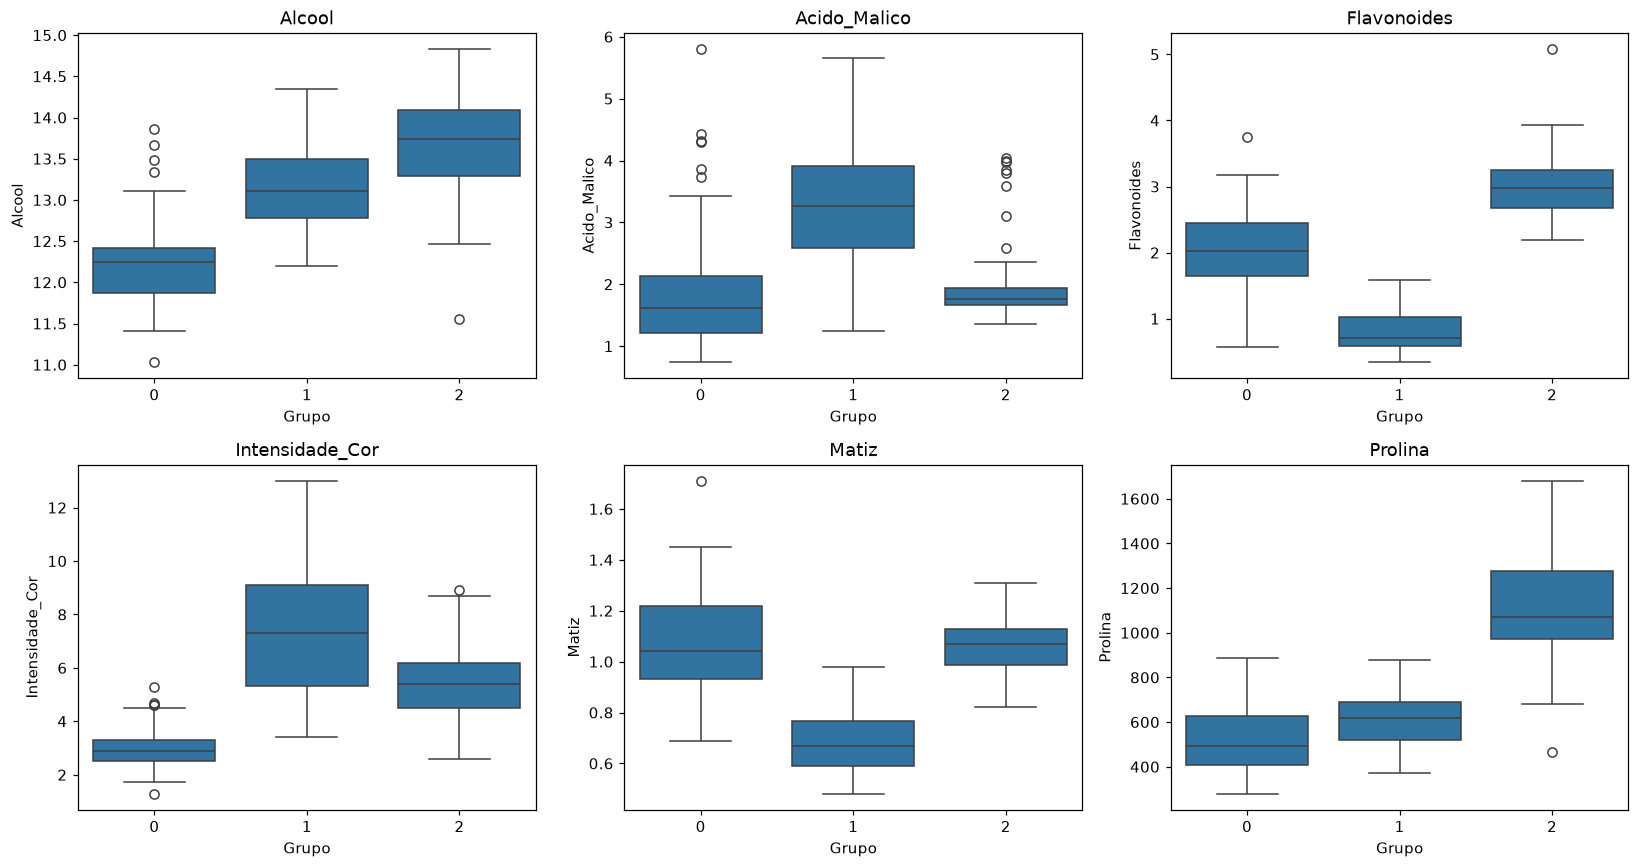

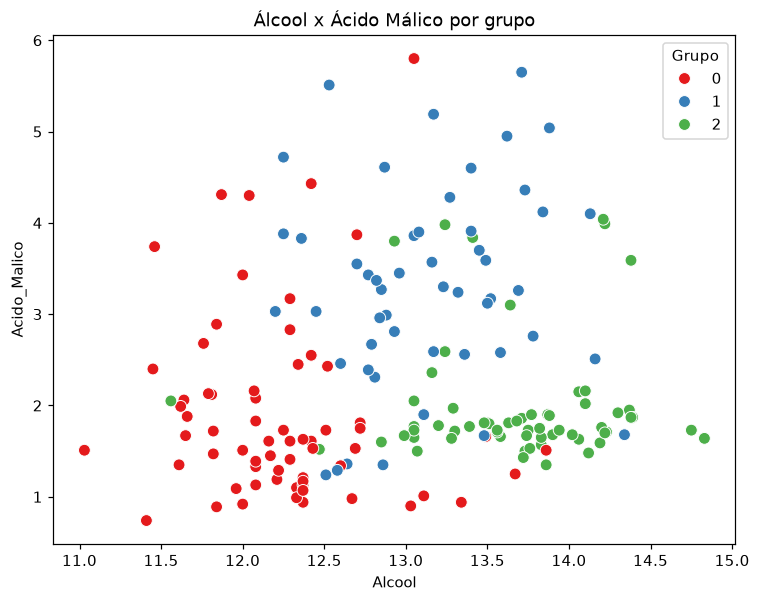

In [ ]:
# ---------- e) Análise dos grupos ----------
# Média de cada variável por grupo, nas unidades originais (não padronizadas)
perfil = df.drop(columns=['Classe']).groupby('Grupo').mean().round(2)
print(perfil.T.to_string())

print("Teor alcoólico médio por grupo:")
print(perfil['Alcool'])
print(f"\nGrupo com maior teor alcoólico: {perfil['Alcool'].idxmax()}")
print(f"Grupo mais ácido (maior ácido málico): {perfil['Acido_Malico'].idxmax()}")
print(f"Grupo com mais cinzas: {perfil['Cinzas'].idxmax()}")
print(f"Grupo com cor mais intensa: {perfil['Intensidade_Cor'].idxmax()}")

# Boxplots das variáveis que mais diferenciam os grupos
variaveis = ['Alcool', 'Acido_Malico', 'Flavonoides', 'Intensidade_Cor', 'Matiz', 'Prolina']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, var in zip(axes.flat, variaveis):
    sns.boxplot(data=df, x='Grupo', y=var, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

# Dispersão Álcool x Ácido Málico, colorida por grupo
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Alcool', y='Acido_Malico', hue='Grupo', palette='Set1', s=60)
plt.title('Álcool x Ácido Málico por grupo')
plt.show()


Resumo dos grupos (médias nas unidades da base):
       Quantidade  Alcool  Acido_Malico  Cinzas  Intensidade_Cor  Flavonoides  Prolina
Grupo                                                                                 
0              65   12.25          1.90    2.23             2.97         2.05   510.17
1              51   13.13          3.31    2.42             7.23         0.82   619.06
2              62   13.68          2.00    2.47             5.45         3.00  1100.23
Grupo 0: 65 vinhos; álcool médio 12.25%; ácido málico 1.90; cinzas 2.23; intensidade de cor 2.97.
Grupo 1: 51 vinhos; álcool médio 13.13%; ácido málico 3.31; cinzas 2.42; intensidade de cor 7.23.
Grupo 2: 62 vinhos; álcool médio 13.68%; ácido málico 2.00; cinzas 2.47; intensidade de cor 5.45.
Maior silhueta entre os k avaliados: k=3, score=0.2849.
O cotovelo é uma avaliação visual; sua posição não é uma prova de um número ideal universal.
A silhueta observada indica separação moderada/limitada; há sobreposição

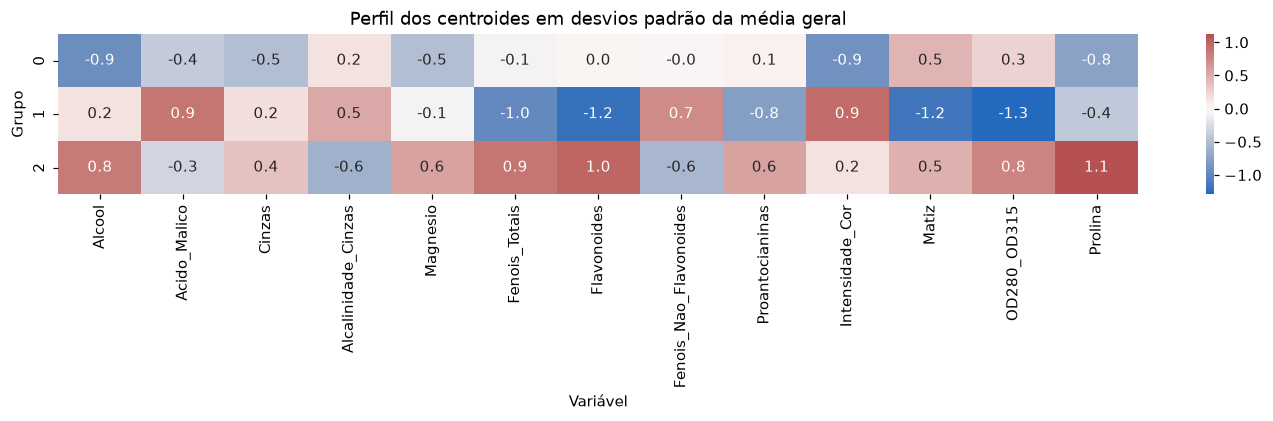

In [ ]:
# ---------- Complemento da análise e conclusão ----------
# Ácido málico é um indicador de composição, não uma medida de pH ou acidez total.
# Os números dos grupos são identificadores arbitrários, sem ordem de qualidade.
print("\nResumo dos grupos (médias nas unidades da base):")
resumo = perfil[['Alcool', 'Acido_Malico', 'Cinzas', 'Intensidade_Cor', 'Flavonoides', 'Prolina']].copy()
resumo.insert(0, 'Quantidade', df.groupby('Grupo').size())
print(resumo.to_string())
for grupo, linha in resumo.iterrows():
    print(f"Grupo {grupo}: {int(linha['Quantidade'])} vinhos; álcool médio {linha['Alcool']:.2f}%; "
          f"ácido málico {linha['Acido_Malico']:.2f}; cinzas {linha['Cinzas']:.2f}; "
          f"intensidade de cor {linha['Intensidade_Cor']:.2f}.")
melhor_k = list(ks)[int(np.argmax(silhuetas))]
print(f"Maior silhueta entre os k avaliados: k={melhor_k}, score={max(silhuetas):.4f}.")
print('O cotovelo é uma avaliação visual; sua posição não é uma prova de um número ideal universal.')
print('A silhueta observada indica separação moderada/limitada; há sobreposição entre grupos.')
print('A padronização dá peso comparável às 13 variáveis. A classe original não participou do ajuste nem da escolha de k.')
print('K-means é sensível a escala, outliers e inicialização; os grupos não indicam qualidade ou causalidade.')

# Perfil padronizado: zero representa a média geral da amostra.
centros = pd.DataFrame(kmeans.cluster_centers_, columns=X.columns)
plt.figure(figsize=(13, 4))
sns.heatmap(centros, cmap='vlag', center=0, annot=True, fmt='.1f')
plt.title('Perfil dos centroides em desvios padrão da média geral')
plt.xlabel('Variável')
plt.ylabel('Grupo')
plt.tight_layout()
plt.show()

# Arquivos auxiliares para consulta e reprodução da análise.
perfil.to_csv(base / 'perfil_grupos.csv', encoding='utf-8-sig')
df.to_csv(base / 'vinhos_com_grupos.csv', index=False, encoding='utf-8-sig')
pd.DataFrame({'k': list(ks), 'inercia': inercias, 'silhueta': silhuetas}).to_csv(
    base / 'comparacao_k.csv', index=False)

## Conclusão dos grupos

- **Grupo 0 (65 vinhos):** menor álcool médio (12,25%), menor intensidade de cor (2,97), menos cinzas (2,23) e menor prolina (510,17).
- **Grupo 1 (51 vinhos):** maior ácido málico médio (3,31), maior intensidade de cor (7,23), menos flavonoides (0,82) e menor matiz (0,69). É o grupo com maior ácido málico, sem inferir pH ou acidez total.
- **Grupo 2 (62 vinhos):** maior álcool médio (13,68%), mais prolina (1100,23), flavonoides (3,00), fenóis totais (2,85), magnésio (107,97) e cinzas (2,47).

O Elbow sugere uma mudança de ritmo por volta de k=3 e a silhueta alcança seu maior valor entre os k testados em **k=3 (0,2849)**. A separação é limitada, com sobreposição: não são categorias perfeitamente distintas. Os boxplots e os centroides ajudam a observar diferenças de composição; o gráfico com duas variáveis é apenas uma projeção das 13 utilizadas.

O procedimento atende aos itens a-e de ML. Os números dos grupos são arbitrários. Não é possível concluir qualidade, causalidade ou generalização para outros vinhos apenas com esta amostra.
